# Getting started with `da6idb`

Reading and processing the files from APS 6-ID-B, with no viewer involved.

This runs against `tise2_2_00152`, the scan that travels with the repository:
a 101-point `psic_eta` rocking curve with its detector stack. Point
`FOLDER` somewhere else and the rest should follow.

In [1]:
import sys
from pathlib import Path

import numpy as np

# This notebook lives in examples/, so da6idb is one level up. Installing the
# package (pip install -e . from the repository root) makes this unnecessary,
# but the notebook should run either way.
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
try:
    import da6idb
except ModuleNotFoundError:
    sys.path.insert(0, str(REPO))
    import da6idb

FOLDER = REPO                # the repository root, which holds the example scan
SCAN = 152

## What is in the folder\n\n`open_folder` lists the scans; `summary()` is a DataFrame.

In [2]:
folder = da6idb.open_folder(FOLDER)
folder.summary().head(10)

,plan,motors,range,points,count_time,image,file
scan,,,,,,,
6,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 0→100 (101); rp100_ou...,101,1.0,True,tise2_2_00006_master.hdf
7,rel_scan,psic_eta,psic_eta 19.6295→23.6296 (101),101,1.0,True,tise2_2_00007_master.hdf
8,rel_scan,psic_eta,psic_eta 31.7869→35.787 (101),101,1.0,True,tise2_2_00008_master.hdf
9,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 100→0 (101); rp100_ou...,101,1.0,True,tise2_2_00009_master.hdf
10,rel_scan,psic_eta,psic_eta 31.8999→35.9 (101),101,1.0,True,tise2_2_00010_master.hdf
11,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 0→-50 (101); rp100_ou...,101,1.0,True,tise2_2_00011_master.hdf
34,grid_scan,"psic_eta, psic_chi",psic_eta 9.9→10.1 (25); psic_chi 89.9→90.1 (25),25,1.0,True,lineup_00034_master.hdf
83,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 50→-50 (101); rp100_o...,101,1.0,True,tise2_2_00083_master.hdf
151,rel_scan,cryo_z,cryo_z -1.49989→-1.09987 (41),41,1.0,True,tise2_2_00151_master.hdf


## One scan\n\nIndexing by scan number gives a `Scan`.

In [3]:
scan = folder[SCAN]
scan

<Scan 00152 'rel_scan' psic_eta — 101 points>

In [4]:
scan.hkl_position()     # where the diffractometer was, averaged over the scan

,mean,spread
axis,,
H,1.013464,0.002557
K,-0.492560,0.038620
L,7.484036,0.001328


## Which field is which

`fields` lists every name in the stream and says what it is, so you do not have
to guess at the names for x, y and `normalise`. The motor the scan moved comes
first, the detector the plan nominated (`hinted`) next, and the fields that
never moved last -- a channel that barely varies around a large positive value,
like an ion chamber, is your monitor.

In [5]:
scan.fields()

,role,hinted,units,varies,min,max,source
field,,,,,,,
psic_eta,scanned,False,degrees,True,2.069174e+01,2.269179e+01,PV:6idb1:m17.RBV
lambda250k_stats3_total,detector,True,,True,2.494060e+05,3.134790e+05,PV:s6lambda1:Stats3:Total_RBV
EPOCH,time,False,,True,1.790516e+09,1.790516e+09,
INDEX,index,False,,True,0.000000e+00,1.000000e+02,
Ion Chamber 4,detector,False,,True,1.338390e+05,1.342080e+05,PV:6idb1:scaler1.S5
Sawtooth_Bottom,detector,False,,True,1.442997e+06,1.443032e+06,PV:6idb1:scaler1.S6
ah2700a_capacitance,detector,False,,True,8.892000e-01,8.896600e-01,PV:6idb1:AH2700A:1:CAP
ah2700a_loss,detector,False,,True,0.000000e+00,1.800000e-03,PV:6idb1:AH2700A:1:LOSS
lambda250k_stats1_total,detector,False,,True,1.450500e+04,4.153100e+04,PV:s6lambda1:Stats1:Total_RBV


In [6]:
# just the plottable ones
table = scan.fields()
table[table["varies"] == True]

,role,hinted,units,varies,min,max,source
field,,,,,,,
psic_eta,scanned,False,degrees,True,2.069174e+01,2.269179e+01,PV:6idb1:m17.RBV
lambda250k_stats3_total,detector,True,,True,2.494060e+05,3.134790e+05,PV:s6lambda1:Stats3:Total_RBV
EPOCH,time,False,,True,1.790516e+09,1.790516e+09,
INDEX,index,False,,True,0.000000e+00,1.000000e+02,
Ion Chamber 4,detector,False,,True,1.338390e+05,1.342080e+05,PV:6idb1:scaler1.S5
Sawtooth_Bottom,detector,False,,True,1.442997e+06,1.443032e+06,PV:6idb1:scaler1.S6
ah2700a_capacitance,detector,False,,True,8.892000e-01,8.896600e-01,PV:6idb1:AH2700A:1:CAP
ah2700a_loss,detector,False,,True,0.000000e+00,1.800000e-03,PV:6idb1:AH2700A:1:LOSS
lambda250k_stats1_total,detector,False,,True,1.450500e+04,4.153100e+04,PV:s6lambda1:Stats1:Total_RBV


## Curves

`curve` takes an x field and any number of y fields, and normalises if asked.
Left to itself it uses the motor the scan moved -- or the point index, for a
plan that moved nothing.

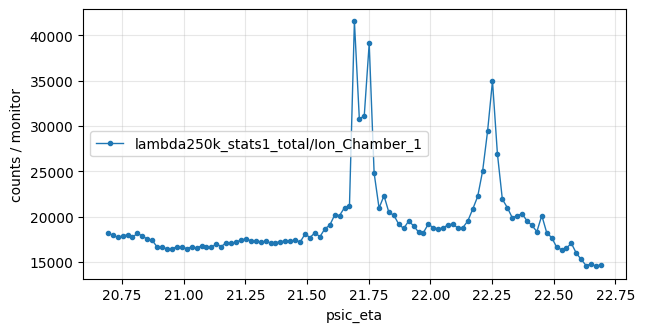

In [7]:
curve = scan.curve(y="lambda250k_stats1_total", normalise="Ion_Chamber_1")
ax = curve.plot(marker="o", ms=3, lw=1, figsize=(7, 3.5))
ax.set_ylabel("counts / monitor"); ax.grid(alpha=0.3)

In [8]:
scan.statistics("lambda250k_stats1_total")   # max, min, half-max centre and FWHM

,max_y,max_x,min_y,min_x,center,fwhm
lambda250k_stats1_total,41531.0,21.691766,14505.0,22.671743,21.722856,0.088734


## The detector frames

`images()` finds the detector file the way the viewers do, and brings the
ROIs the beamline recorded -- from the image file, or from the master's
baseline when the image has none.

In [9]:
images = scan.images()
print(images)
images.rois

<Images pva_tise2_2_00152.h5 — 101 x 516x516>


,name,x,y,w,h,angle
0,ROI1,286.0,335.0,50.0,5.0,0.0
1,ROI2,286.0,330.0,50.0,15.0,0.0
2,ROI3,111.0,333.0,400.0,10.0,0.0
3,ROI4,111.0,328.0,400.0,20.0,0.0


In [10]:
# every metric for ROI 1, frame by frame -- the same arithmetic the viewer runs
images.roi_series(0).head()

,sum,mean,min,max,comx,comy
frame,,,,,,
0,18152.0,72.608,20.0,128.0,24.369216,1.984134
1,17950.0,71.800,23.0,120.0,25.037047,1.959443
2,17688.0,70.752,22.0,123.0,24.960934,1.958390
3,17869.0,71.476,12.0,125.0,25.233309,1.968101
4,17972.0,71.888,25.0,162.0,25.629145,2.004618


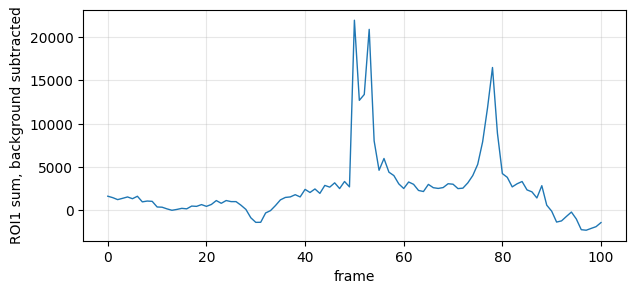

In [11]:
ax = images.roi_curve(0, "sum", background=2).plot(figsize=(7, 3), lw=1)
ax.set_ylabel("ROI1 sum, background subtracted"); ax.grid(alpha=0.3)

## Reciprocal space

`hkl()` gathers the geometry from the master, the image file and any
`hkl_setup.json` in the folder, and says where each piece came from.

In [12]:
m = scan.hkl()
m.sources()

angles              image
center_pixel       master
detector_dirs       image
detector_size       image
distance           master
energy_kev         master
inplane             image
pixel_direction    master
primary_beam        image
sample_dirs         image
surface             image
transmission        image
ub                 master
Name: source, dtype: str

In [13]:
m.resolution()    # the cell the sampling supports, and what that was measured from

volume_per_sample    3.011909e-10
frame_gap            1.235297e-03
in_plane             4.937504e-04
cell                 6.703176e-04
footprint_H          3.645253e-04
footprint_K          1.336434e-03
footprint_L          5.620182e-04
dtype: float64

### A gridded map

`grid()` bins the frames onto a regular lattice and hands back an
`xarray.DataArray` with real H, K and L coordinates. It is cached as the same
`.vti` the viewers read, so a grid made here opens there.

`oversample` scales the automatic cell size; 4 keeps this example quick.

In [14]:
cube = m.grid(oversample=4.0)
cube

<xarray.DataArray 'intensity' (H: 91, K: 106, L: 138)> Size: 5MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(91, 106, 138), dtype=float32)
Coordinates:
  * H        (H) float64 728B 0.9195 0.9221 0.9248 0.9275 ... 1.154 1.157 1.16
  * K        (K) float64 848B -0.6344 -0.6318 -0.6291 ... -0.3552 -0.3525
  * L        (L) float64 1kB 7.337 7.34 7.342 7.345 ... 7.697 7.7 7.702 7.705
Attributes:
    hkl_range:               [0.9194757806218079, 1.1596406031317914, -0.6344...
    step:                    [0.0026684980278887105, 0.002685092481490625, 0....
    width:                   [0.0003645252675839039, 0.0013364335217694867, 0...
    source_image:            pva_tise2_2_00152.h5
    source_master:           tise2_2_00152_master.hdf
    frames:                  101
    frame_range:             [0, -1, 1]
    geometry:                f203f0cd17684188
    oversample:              4.0
    transmission_corrected:  0
    filled_cells:            [445490, 1331148]
    path:                    /Users/jwkim/Library/CloudStorage/Box-Box/python...

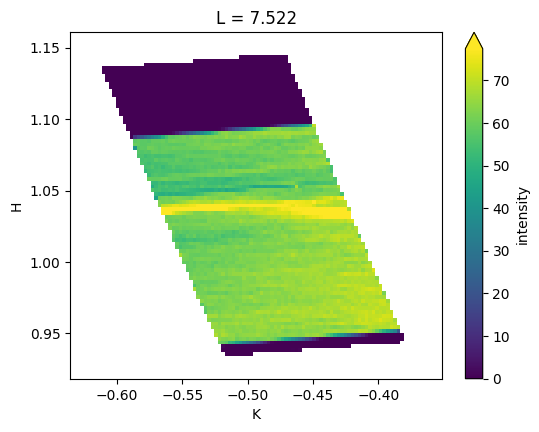

In [15]:
# select by coordinate rather than by index, and let xarray draw it
plane = cube.sel(L=float(cube.L[len(cube.L) // 2]), method="nearest")
plane.plot(figsize=(6, 4.5), robust=True)

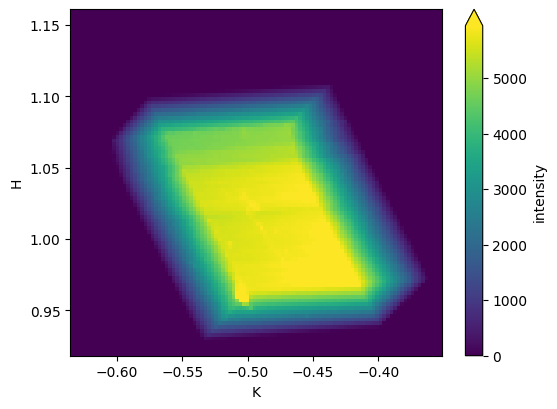

In [16]:
# or sum along an axis
cube.sum("L", skipna=True).plot(figsize=(6, 4.5), robust=True)

### Slices and cuts

`slice` cuts a plane at any angle, averaging over a slab of cells if asked.
Where an image axis runs along H, K or L it is labelled with it.

('K', 'H') (107, 91)


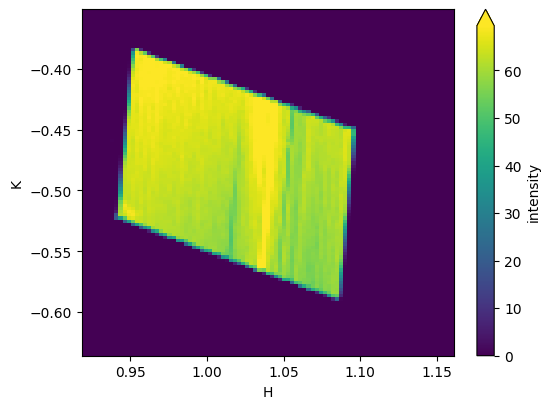

In [17]:
sl = m.slice(normal=(0, 0, 1), offset=0.0, layers=3)
print(sl.dims, sl.shape)
sl.plot(figsize=(6, 4.5), robust=True)

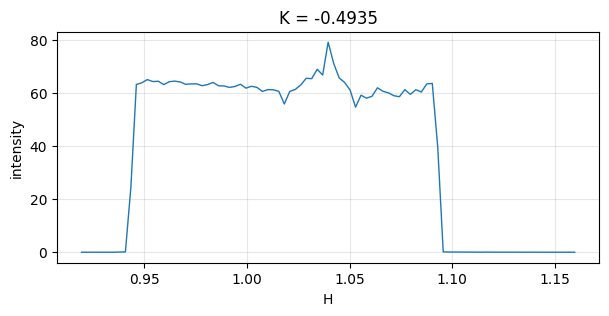

In [18]:
# a line through the slice is a one-liner once it is labelled
cut = sl.sel({sl.dims[0]: sl[sl.dims[0]][len(sl[sl.dims[0]]) // 2]}, method="nearest")
ax = cut.plot(figsize=(7, 3), lw=1); import matplotlib.pyplot as plt; plt.grid(alpha=0.3)

### Writing it out\n\nText, CSV, `.npz` or HDF5, each with a header saying where it came from.

In [19]:
from da6idb import export

out = export.write_dataarray(sl, "slice.txt")
print(out, "\n")
print("\n".join(open(out).read().splitlines()[:6]))

slice.txt 

# intensity from da6idb
# offset: 0.0
# layers: 3
# x axis: H  from 0.919476 to 1.159641  (91 points, step 0.0026685)
# y axis: K  from -0.634439 to -0.352504  (107 points, step 0.00265976)
# rows run along y, columns along x; unmeasured cells are nan


## A run of scans

`grid_scans` measures the cell size once, from the first scan, and reuses it
for the rest -- so with a common HKL range every grid shares origin, spacing
and shape, and they can be compared cell for cell.

In [20]:
from da6idb import batch

print(batch.expand_scans(152, 160, 2))
# batch.grid_scans(FOLDER, [152, 153], hkl_range=(0.95, 1.10, -0.60, -0.40, 7.40, 7.65))

[152, 154, 156, 158, 160]
